In [5]:
## Step 1: Import the required libraries 

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

### Activity 1: Dataset Summary 
 Display the number of rows and columns. 

 List all column names and their data types. 

 Generate descriptive statistics. 

 Identify the number of unique talks, where a suitable identifier is available.

In [6]:
df = pd.read_csv('../data/processed/ted_talks_eda.csv')

In [7]:
df.head()

,talk_id,title,speaker_1,duration,topics,url,description,transcript
0,1,Averting the climate crisis,Al Gore,16.28,"['alternative energy', 'cars', 'climate change...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,19.83,"['Africa', 'Asia', 'Google', 'demo', 'economic...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,21.43,"['computers', 'entertainment', 'interface desi...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,18.60,"['MacArthur grant', 'activism', 'business', 'c...",https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today â€” and I'm very happy th...
4,66,Do schools kill creativity?,Sir Ken Robinson,19.40,"['children', 'creativity', 'culture', 'dance',...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


In [8]:
print("Number of rows:", df.shape[0]) 

Number of rows: 4005


In [9]:
print("Number of cols:", df.shape[1]) 

Number of cols: 8


In [10]:
df.columns.to_list()

['talk_id',
 'title',
 'speaker_1',
 'duration',
 'topics',
 'url',
 'description',
 'transcript']

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   talk_id      4005 non-null   int64  
 1   title        4005 non-null   str    
 2   speaker_1    4005 non-null   str    
 3   duration     4005 non-null   float64
 4   topics       4005 non-null   str    
 5   url          4005 non-null   str    
 6   description  4005 non-null   str    
 7   transcript   4005 non-null   str    
dtypes: float64(1), int64(1), str(6)
memory usage: 250.4 KB


In [12]:
df.describe()

,talk_id,duration
count,4005.000000,4005.000000
mean,12432.538327,12.066871
std,17447.576262,6.029596
min,1.000000,1.000000
25%,1252.000000,6.550000
50%,2333.000000,12.300000
75%,23777.000000,16.230000
max,62794.000000,65.370000


In [13]:
print("Number of unique talks: ", df['talk_id'].nunique())

Number of unique talks:  4005


### Activity 2: Missing Values and Duplicates 

 Calculate missing-value counts and percentages for each column. 

 Identify duplicate rows and repeated talk identifiers, if available. 

 Identify missing or empty titles, descriptions, tags, transcripts, and URLs. 

 Explain which missing fields may affect the recommendation system. 

In [14]:
df.isnull().sum()

talk_id        0
title          0
speaker_1      0
duration       0
topics         0
url            0
description    0
transcript     0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

### Activity 3: Text Analysis 
Where the relevant columns are available: 

 Analyze transcript and description lengths. 

 Calculate word counts. 

 Identify empty or unusually short text entries. 

 Visualize the distribution of transcript lengths. 

In [16]:
# Calculate Character Lengths and Word Counts

required_columns = ['description','transcript'] 

for col in required_columns:
    df[f"{col}_char_count"] = df[col].str.len()

    df[f"{col}_word_count"] = df[col].apply(
        lambda text: len(text.split())
    )

In [17]:
# Display Descriptive Statistics

length_columns = [
    "description_char_count",
    "description_word_count",
    "transcript_char_count",
    "transcript_word_count",
]

print("\nTEXT LENGTH STATISTICS")
print(df[length_columns].describe().round(2))


TEXT LENGTH STATISTICS
       description_char_count  description_word_count  transcript_char_count  \
count                 4005.00                 4005.00                4005.00   
mean                   353.64                   58.20               10019.45   
std                    115.74                   19.43                5288.23   
min                     52.00                    9.00                  18.00   
25%                    259.00                   43.00                5196.00   
50%                    349.00                   57.00                9853.00   
75%                    435.00                   72.00               13643.00   
max                    907.00                  143.00               57748.00   

       transcript_word_count  
count                4005.00  
mean                 1790.59  
std                   966.29  
min                     2.00  
25%                   928.00  
50%                  1753.00  
75%                  2445.00  
max    

In [18]:
# Identify Empty Text Entries

for col in required_columns:
    empty_count = df[col].eq("").sum()

    print(f"\nEmpty {col} entries: {empty_count}")


Empty description entries: 0

Empty transcript entries: 0


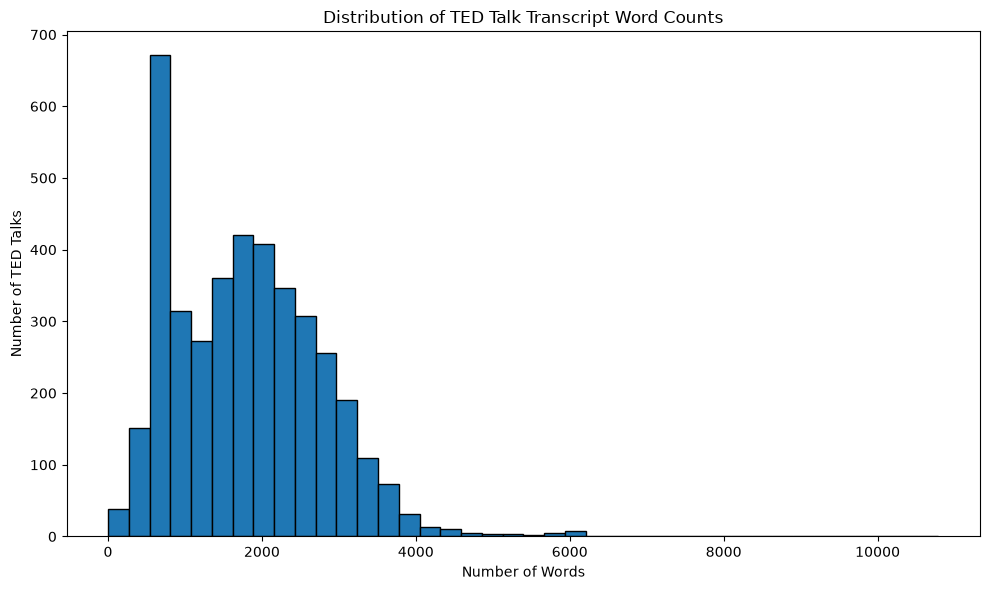

In [19]:
# Visualize Transcript Length Distribution
# The distribution shows how TED Talks vary in transcript word counts, 
# helping us understand whether most talks are short or long 
# and whether unusually short or lengthy transcripts exist.

plt.figure(figsize=(10, 6))

plt.hist(
    df["transcript_word_count"],
    bins=40,
    edgecolor="black",
)

plt.title("Distribution of TED Talk Transcript Word Counts")
plt.xlabel("Number of Words")
plt.ylabel("Number of TED Talks")
plt.tight_layout()
plt.show()

### Activity 4: Tag and Topic Analysis 

 Identify the most frequently occurring TED Talk tags or topics. 

 Display the top 10–15 tags in a chart. 

 Explain which topics appear most frequently. 

 Document the format in which tags are stored and how they were processed. 

In [20]:
df['topics'].nunique()

3977

In [21]:
df['topics']

0       ['alternative energy', 'cars', 'climate change...
1       ['Africa', 'Asia', 'Google', 'demo', 'economic...
2       ['computers', 'entertainment', 'interface desi...
3       ['MacArthur grant', 'activism', 'business', 'c...
4       ['children', 'creativity', 'culture', 'dance',...
                              ...                        
4000    ['activism', 'data', 'technology', 'mental hea...
4001    ['TED-Ed', 'education', 'history', 'animation'...
4002    ['society', 'law', 'policy', 'justice system',...
4003    ['TED-Ed', 'education', 'animation', 'United S...
4004    ['animals', 'TED-Ed', 'animation', 'oceans', '...
Name: topics, Length: 4005, dtype: str

In [22]:
# Parse Topics into Individual Tags
import ast
import json
import re
from collections import Counter

def extract_topics(value):
    """Convert a topics cell into a list of individual topic strings."""

    if pd.isna(value):
        return []

    # Handle values that are already lists
    if isinstance(value, (list, tuple, set)):
        items = list(value)

    elif isinstance(value, str):
        value = value.strip()

        if not value:
            return []

        # Try parsing list/dictionary-like representations
        parsed = None

        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            try:
                parsed = json.loads(value)
            except (ValueError, json.JSONDecodeError):
                pass

        if isinstance(parsed, dict):
            items = list(parsed.values())
        elif isinstance(parsed, (list, tuple, set)):
            items = list(parsed)
        elif isinstance(parsed, str):
            items = [parsed]
        else:
            # Fallback for ordinary comma-separated text
            items = re.split(r"[,;|]", value)

    else:
        return []

    # Clean individual tags and remove duplicates per talk
    cleaned = []

    for item in items:
        if not isinstance(item, str):
            continue

        tag = item.strip().strip("'\"").strip()

        if tag:
            cleaned.append(tag)

    # Preserve original spelling while avoiding duplicate tags
    return list(dict.fromkeys(cleaned))

In [23]:
df["topics_list"] = df["topics"].apply(extract_topics)

### Why do we need both - topics & topics_list?
- topics preserves the original data.
- topics_list makes it easier to count individual topics, find shared interests, and filter TED Talks by topic.

In [24]:
df['topics_list'].head()

0    [alternative energy, cars, climate change, cul...
1    [Africa, Asia, Google, demo, economics, global...
2    [computers, entertainment, interface design, m...
3    [MacArthur grant, activism, business, cities, ...
4    [children, creativity, culture, dance, educati...
Name: topics_list, dtype: object

In [25]:
# Calculate Topic Frequencies

topic_counter = Counter(
    topic
    for topic_list in df["topics_list"]
    for topic in topic_list
)

topic_frequency = pd.DataFrame(
    topic_counter.items(),
    columns=["topic", "frequency"],
)

topic_frequency = topic_frequency.sort_values(
    by="frequency",
    ascending=False,
).reset_index(drop=True)

top_15 = topic_frequency.head(15)

print("\nTop 15 TED Talk Topics:")
print(top_15.to_string(index=False))


Top 15 TED Talk Topics:
        topic  frequency
      science        993
   technology        979
      culture        680
         TEDx        581
global issues        574
       TED-Ed        563
      society        557
       design        518
social change        512
    animation        487
     business        443
       health        442
      history        406
    education        390
     humanity        388


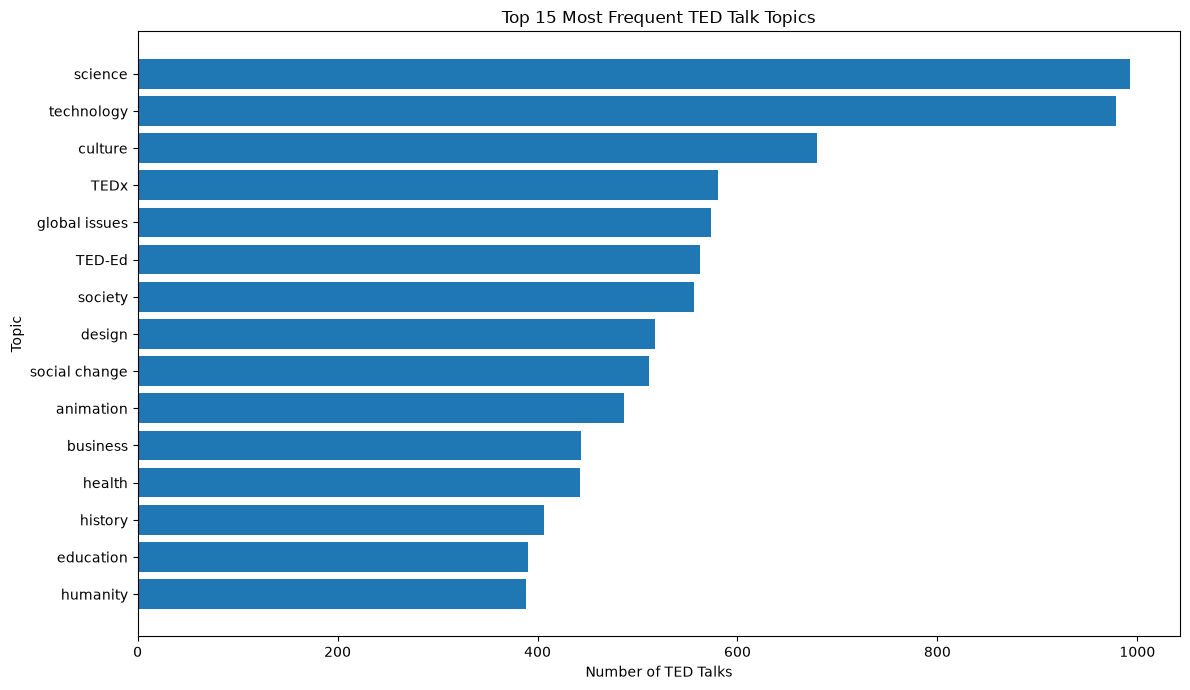

In [26]:
# 6. Visualize Top 15 Topics

if not top_15.empty:
    plt.figure(figsize=(12, 7))

    plt.barh(
        top_15["topic"].iloc[::-1],
        top_15["frequency"].iloc[::-1],
    )

    plt.title("Top 15 Most Frequent TED Talk Topics")
    plt.xlabel("Number of TED Talks")
    plt.ylabel("Topic")
    plt.tight_layout()
    plt.show()

In [27]:
df.head()

,talk_id,title,speaker_1,duration,topics,url,description,transcript,description_char_count,description_word_count,transcript_char_count,transcript_word_count,topics_list
0,1,Averting the climate crisis,Al Gore,16.28,"['alternative energy', 'cars', 'climate change...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",233,39,11930,2153,"[alternative energy, cars, climate change, cul..."
1,92,The best stats you've ever seen,Hans Rosling,19.83,"['Africa', 'Asia', 'Google', 'demo', 'economic...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...",172,26,17469,3174,"[Africa, Asia, Google, demo, economics, global..."
2,7,Simplicity sells,David Pogue,21.43,"['computers', 'entertainment', 'interface desi...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...",204,31,18495,3371,"[computers, entertainment, interface design, m..."
3,53,Greening the ghetto,Majora Carter,18.60,"['MacArthur grant', 'activism', 'business', 'c...",https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today â€” and I'm very happy th...,213,31,18340,3071,"[MacArthur grant, activism, business, cities, ..."
4,66,Do schools kill creativity?,Sir Ken Robinson,19.40,"['children', 'creativity', 'culture', 'dance',...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,149,21,17590,3170,"[children, creativity, culture, dance, educati..."


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   talk_id                 4005 non-null   int64  
 1   title                   4005 non-null   str    
 2   speaker_1               4005 non-null   str    
 3   duration                4005 non-null   float64
 4   topics                  4005 non-null   str    
 5   url                     4005 non-null   str    
 6   description             4005 non-null   str    
 7   transcript              4005 non-null   str    
 8   description_char_count  4005 non-null   int64  
 9   description_word_count  4005 non-null   int64  
 10  transcript_char_count   4005 non-null   int64  
 11  transcript_word_count   4005 non-null   int64  
 12  topics_list             4005 non-null   object 
dtypes: float64(1), int64(5), object(1), str(6)
memory usage: 406.9+ KB


In [29]:
df.to_csv("../data/processed/ted_talks_quality_checked.csv", index=False)